<a href="https://colab.research.google.com/github/HanneV09/groepswerk_large_scale_analysis_groep_28/blob/main/LSABD_groepswerk_part1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# 1. Bestanden inladen
metadata = pd.read_csv('sample_metadata.csv')
proteins = pd.read_csv('proteins_npx_raw.csv')
annotations = pd.read_csv('protein_annotation.csv')

# 2. Metadata-kolommen direct hernoemen om verwarring te voorkomen
metadata = metadata.rename(columns={
    'subject.biologicalSex': 'gender',
    'sample.subjectAgeAtDraw': 'age'
})

print(f"Metadata stalen: {metadata.shape} | Eiwitten gemeten: {proteins.shape[1] - 1}")

Metadata stalen: (867, 76) | Eiwitten gemeten: 1481


In [ ]:
# Selecteer alle eiwitkolommen
protein_cols = [col for col in proteins.columns if col != 'sample_kit_id']

# 1. Inspecteer missing values
total_missing = proteins[protein_cols].isnull().sum().sum()
print(f"Totaal aantal ontbrekende NPX-waarden: {total_missing}")

# 2. Mediaan-imputatie per eiwit voor ontbrekende NPX-waarden
proteins_imputed = proteins.copy()
proteins_imputed[protein_cols] = proteins_imputed[protein_cols].fillna(proteins_imputed[protein_cols].median())

# 3. Metadata en eiwitexpressie samenvoegen op sample_kit_id
df_merged = pd.merge(metadata, proteins_imputed, on='sample_kit_id')
print("Vorm van samengevoegde dataset (stalen, variabelen):", df_merged.shape)

Totaal aantal ontbrekende NPX-waarden: 10486
Vorm van samengevoegde dataset (stalen, variabelen): (867, 1557)


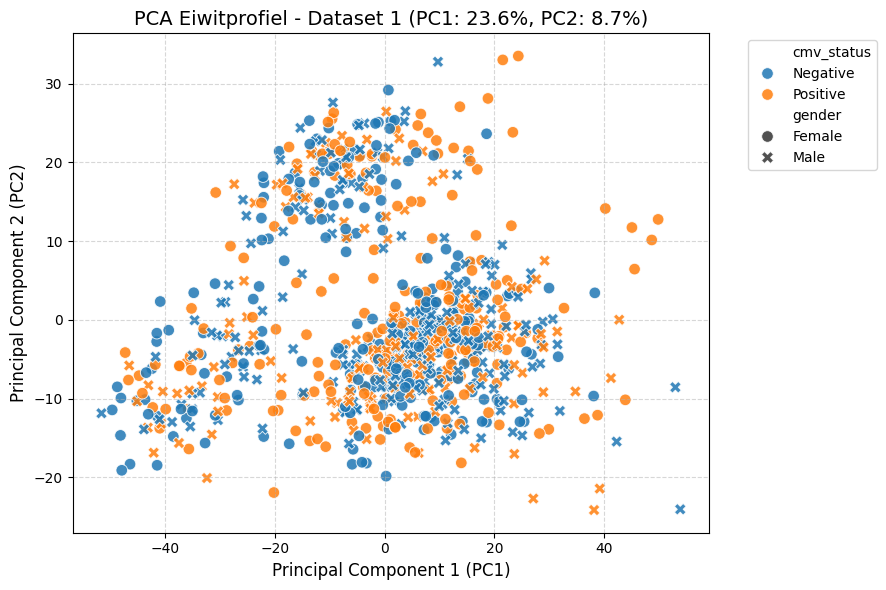

In [ ]:
# 1. Z-score standaardisatie van de eiwitmatrix vóór PCA
X_scaled = StandardScaler().fit_transform(df_merged[protein_cols])

# 2. PCA uitvoeren (2 componenten)
pca = PCA(n_components=2)
pca_coords = pca.fit_transform(X_scaled)

df_merged['PC1'] = pca_coords[:, 0]
df_merged['PC2'] = pca_coords[:, 1]

# 3. Maken van de individuele percentages voor PC1 en PC2 (met index [0] en [1])
pc1_var = pca.explained_variance_ratio_[0] * 100
pc2_var = pca.explained_variance_ratio_[1] * 100

# 4. Plotten van de PCA scatterplot
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df_merged,
    x='PC1',
    y='PC2',
    hue='cmv_status',
    style='gender',
    alpha=0.85,
    s=70
)

plt.title(f"PCA Eiwitprofiel - Dataset 1 (PC1: {pc1_var:.1f}%, PC2: {pc2_var:.1f}%)", fontsize=14)
plt.xlabel("Principal Component 1 (PC1)", fontsize=12)
plt.ylabel("Principal Component 2 (PC2)", fontsize=12)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()